# Model Hestona – MPDATA 2D

Rozwiązanie równania Hestona dla europejskiej opcji call. Adwekcja jest liczona metodą MPDATA, a dyfuzja (w tym człon mieszany) metodą różnic centralnych. Struktura jest analogiczna do notebooka Blacka-Scholesa: jedna klasa integratora, funkcja `solve_heston` i wykresy.

In [1]:
!pip install pympdata
import os
os.environ["NUMBA_THREADING_LAYER"] = "workqueue"

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

from PyMPDATA import ScalarField, VectorField, Solver, Stepper, Options
from PyMPDATA.boundary_conditions import Extrapolated

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pympdata]


## Solver

Po podstawieniu \(x=\ln S\), \(\tau=T-t\):
\[
V_\tau=\frac12vV_{xx}+\rho\xi vV_{xv}+\frac12\xi^2vV_{vv}
+\left(r-\frac v2\right)V_x+\kappa(\theta-v)V_v-rV.
\]

MPDATA rozwiązuje konserwatywny transport. Dla prędkości transportu
\((-b_x,-b_v)\) pojawia się dodatkowy składnik \(-\kappa V\), dlatego
reakcja ma współczynnik \(\kappa-r\). Dyfuzja jest liczona jawnie
różnicami centralnymi.

In [2]:
class HestonIntegrator:
    def __init__(self, *, K=100., T=1., r=.05, kappa=2., theta=.04,
                 xi=.3, rho=-.7, nx=100, nv=60, nt=1200,
                 S_min=20., S_max=300., v_max=.5, options=None):
        self.K, self.T, self.r = K, T, r
        self.kappa, self.theta, self.xi, self.rho = kappa, theta, xi, rho
        self.nx, self.nv, self.nt = nx, nv, nt
        self.dt = T / nt

        self.x_edges = np.linspace(np.log(S_min), np.log(S_max), nx + 1)
        self.v_edges = np.linspace(0., v_max, nv + 1)
        self.dx = self.x_edges[1] - self.x_edges[0]
        self.dv = self.v_edges[1] - self.v_edges[0]
        self.x = (self.x_edges[:-1] + self.x_edges[1:]) / 2
        self.v = (self.v_edges[:-1] + self.v_edges[1:]) / 2
        self.S = np.exp(self.x)

        initial = np.maximum(self.S[:, None] - K, 0.)
        initial = np.broadcast_to(initial, (nx, nv)).copy()

        options = options or Options(n_iters=2, nonoscillatory=True,
                                    infinite_gauge=True)
        bc = (Extrapolated(), Extrapolated())
        halo = options.n_halo

        courant_x = np.broadcast_to(
            (self.v[None, :] / 2 - r) * self.dt / self.dx,
            (nx + 1, nv)
        ).copy()
        courant_v = np.broadcast_to(
            kappa * (self.v_edges[None, :] - theta) * self.dt / self.dv,
            (nx, nv + 1)
        ).copy()

        assert np.amax(np.abs(courant_x)) <= 1
        assert np.amax(np.abs(courant_v)) <= 1

        stepper = Stepper(options=options, grid=(nx, nv))
        advectee = ScalarField(initial, halo, bc)
        advector = VectorField((courant_x, courant_v), halo, bc)
        self.solver = Solver(stepper, advectee, advector)

        v_eff = min(v_max, max(theta, 0.15))
        a = .5 * v_eff
        c = .5 * xi**2 * v_eff
        d = abs(rho * xi * v_eff)
        bound = 4*a/self.dx**2 + 4*c/self.dv**2 + d/(self.dx*self.dv)
        self.dt_diff = np.inf if bound == 0 else 1.8 / bound

        self._boundaries(0.)

    def get(self):
        return self.solver.advectee.get()

    def _boundaries(self, tau):
        q = self.get()
        q[:, 0] = q[:, 1]
        q[:, -1] = q[:, -2]
        q[0, :] = 0.
        q[-1, :] = self.S[-1] - self.K * np.exp(-self.r * tau)

    def _diffusion(self, q):
        p = np.pad(q, ((1, 1), (1, 1)), mode="edge")
        dxx = (p[2:, 1:-1] - 2*q + p[:-2, 1:-1]) / self.dx**2
        dvv = (p[1:-1, 2:] - 2*q + p[1:-1, :-2]) / self.dv**2
        dxv = (p[2:, 2:] - p[2:, :-2] - p[:-2, 2:] + p[:-2, :-2]) / (4*self.dx*self.dv)
        v = self.v[None, :]
        return .5*v*dxx + self.rho*self.xi*v*dxv + .5*self.xi**2*v*dvv

    def _diffusion_step(self, interval, tau):
        n = max(1, int(np.ceil(interval / self.dt_diff)))
        h = interval / n
        for _ in range(n):
            q = self.get()
            q += h * self._diffusion(q)
            self._boundaries(tau)

    def __call__(self, *, outfreq=200):
        output = [self.get().copy()]
        times = [0.]

        for it in range(1, self.nt + 1):
            tau = it * self.dt

            self._diffusion_step(self.dt/2, tau)
            self.get()[:] *= np.exp((self.kappa - self.r) * self.dt/2)
            self._boundaries(tau)
            self.solver.advance(n_steps=1)
            self._boundaries(tau)
            self.get()[:] *= np.exp((self.kappa - self.r) * self.dt/2)
            self._boundaries(tau)
            self._diffusion_step(self.dt/2, tau)
            self._boundaries(tau)

            if it % outfreq == 0 or it == self.nt:
                output.append(self.get().copy())
                times.append(tau)

        return np.asarray(times), output

## Obliczenia

In [3]:
def solve_heston(**kwargs):
    integrator = HestonIntegrator(**kwargs)
    times, output = integrator(outfreq=max(1, integrator.nt // 4))
    return integrator, times, output


def bs_analytic(S, K, T, r, sigma):
    d1 = (np.log(S/K) + (r + .5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)


params = dict(K=100., T=1., r=.05, kappa=2., theta=.04,
              xi=.3, rho=-.7, nx=100, nv=60, nt=1200,
              S_min=20., S_max=300., v_max=.5)

integrator, times, output = solve_heston(**params)
V = output[-1]

## Wizualizacja rozwiązania dla ustalonych parametrów

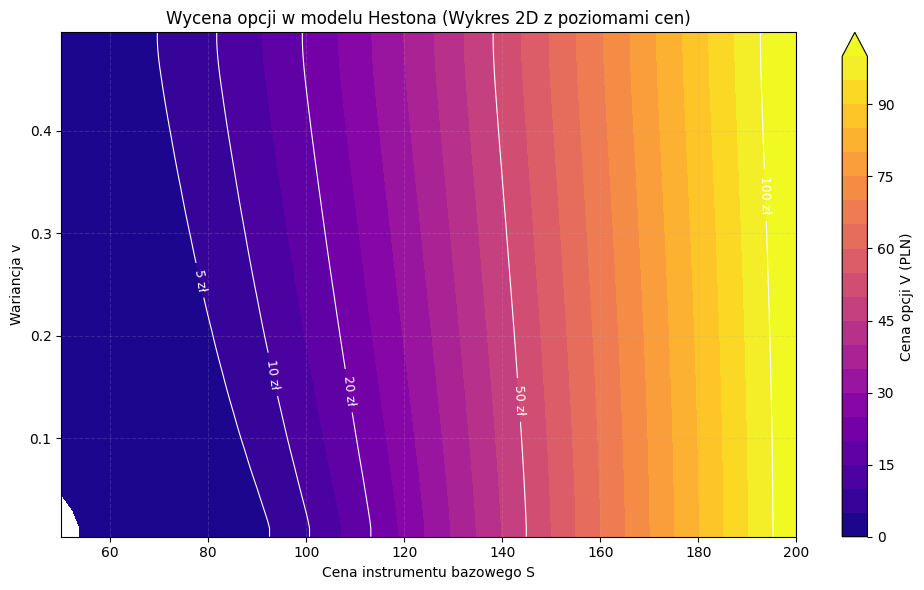

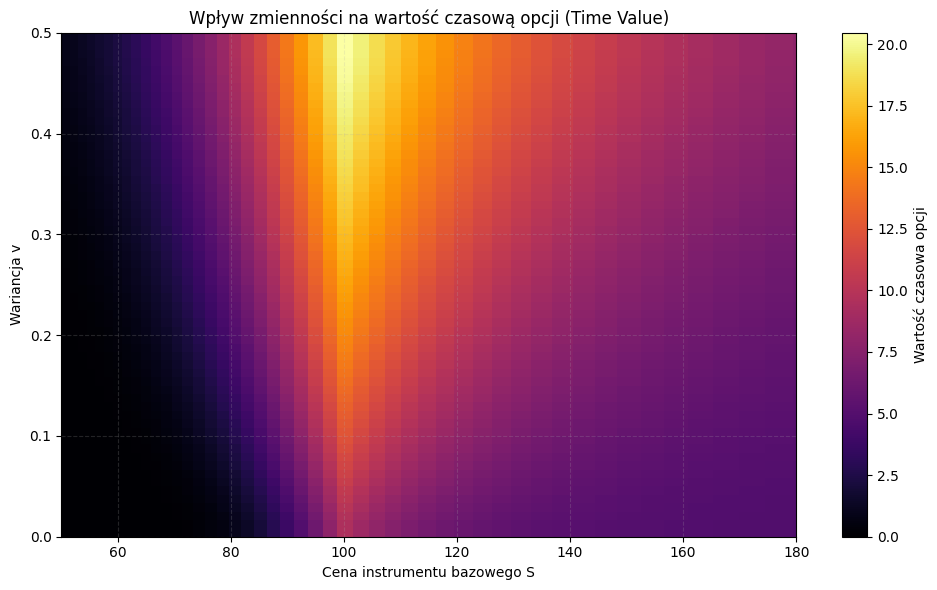

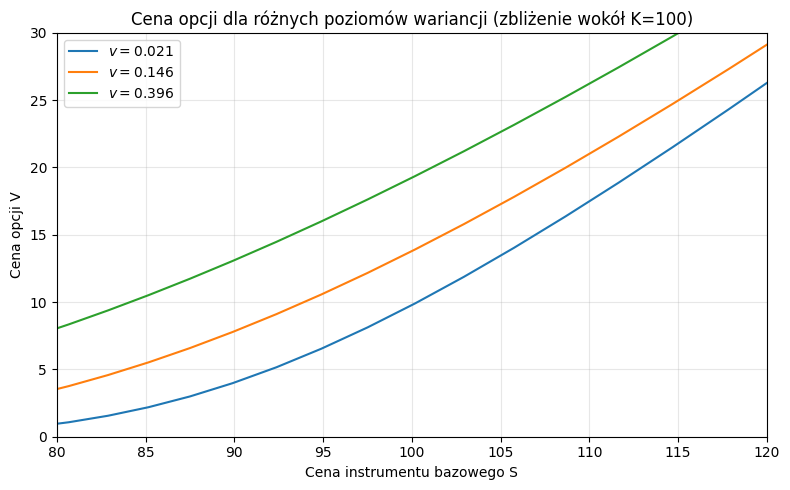

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))

levels = np.linspace(0, 100, 21)
im = ax.contourf(integrator.S, integrator.v, V.T, levels=levels, cmap="plasma", extend="max")
contours = ax.contour(integrator.S, integrator.v, V.T, levels=[5, 10, 20, 50, 100], colors="white", linewidths=0.8)
ax.clabel(contours, inline=True, fontsize=9, fmt="%.0f zł")

fig.colorbar(im, ax=ax, label="Cena opcji V (PLN)")
ax.set_xlim(50, 200)
ax.set(xlabel="Cena instrumentu bazowego S", ylabel="Wariancja v",
       title="Wycena opcji w modelu Hestona (Wykres 2D z poziomami cen)")
ax.grid(True, alpha=0.2, linestyle="--")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
intrinsic_value = np.maximum(integrator.S[:, None] - integrator.K, 0.)
time_value = V - intrinsic_value

im2 = ax.pcolormesh(integrator.S, integrator.v, time_value.T, shading="auto", cmap="inferno")
fig.colorbar(im2, ax=ax, label="Wartość czasowa opcji")
ax.set_xlim(50, 180)
ax.set(xlabel="Cena instrumentu bazowego S", ylabel="Wariancja v",
       title="Wpływ zmienności na wartość czasową opcji (Time Value)")
ax.grid(True, alpha=0.2, linestyle="--")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
variances_to_plot = [0.02, 0.15, 0.40]
for target_v in variances_to_plot:
    j = np.argmin(abs(integrator.v - target_v))
    ax.plot(integrator.S, V[:, j], label=fr"$v={integrator.v[j]:.3f}$")

ax.set_xlim(80, 120)
ax.set_ylim(0, 30)
ax.set(xlabel="Cena instrumentu bazowego S", ylabel="Cena opcji V",
       title="Cena opcji dla różnych poziomów wariancji (zbliżenie wokół K=100)")
ax.grid(alpha=.3)
ax.legend()
fig.tight_layout()
plt.show()

### Wykres 3D dla modelu Hestona

Poniższy kod generuje przestrzenny wykres 3D przedstawiający ceny opcji $V$ oraz wartość czasową (Time Value) w zależności od ceny instrumentu bazowego $S$ oraz wariancji $v$.

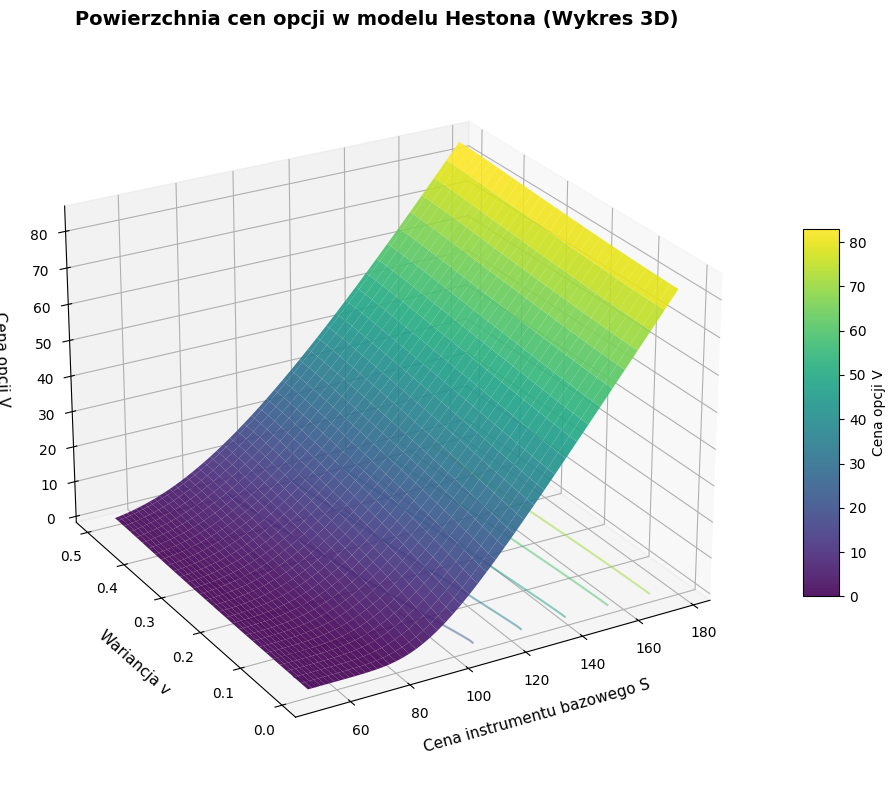

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from collections.abc import Iterable
from mpl_toolkits.mplot3d import Axes3D

mask_S = (integrator.S >= 50) & (integrator.S <= 180)
S_grid = integrator.S[mask_S]
v_grid = integrator.v

S_mesh, v_mesh = np.meshgrid(S_grid, v_grid)
V_mesh = V[mask_S, :].T

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(S_mesh, v_mesh, V_mesh, cmap='viridis', edgecolor='none', alpha=0.9)

cset = ax.contour(S_mesh, v_mesh, V_mesh, zdir='z', offset=0, cmap='viridis', alpha=0.5)

ax.set_xlabel('Cena instrumentu bazowego S', fontsize=11, labelpad=10)
ax.set_ylabel('Wariancja v', fontsize=11, labelpad=10)
ax.set_zlabel('Cena opcji V', fontsize=11, labelpad=10)
ax.set_title('Powierzchnia cen opcji w modelu Hestona (Wykres 3D)', fontsize=14, fontweight='bold', pad=15)

fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='Cena opcji V')

ax.view_init(elev=25, azim=-120)

plt.tight_layout()
plt.show()

### Wykres 3D Wartości Czasowej (Zmienności Implikowanej)

Aby jeszcze wyraźniej pokazać sam wpływ zmienności bez dominującego trendu ceny akcji, możemy zwizualizować wartość czasową opcji (Time Value) w 3D:

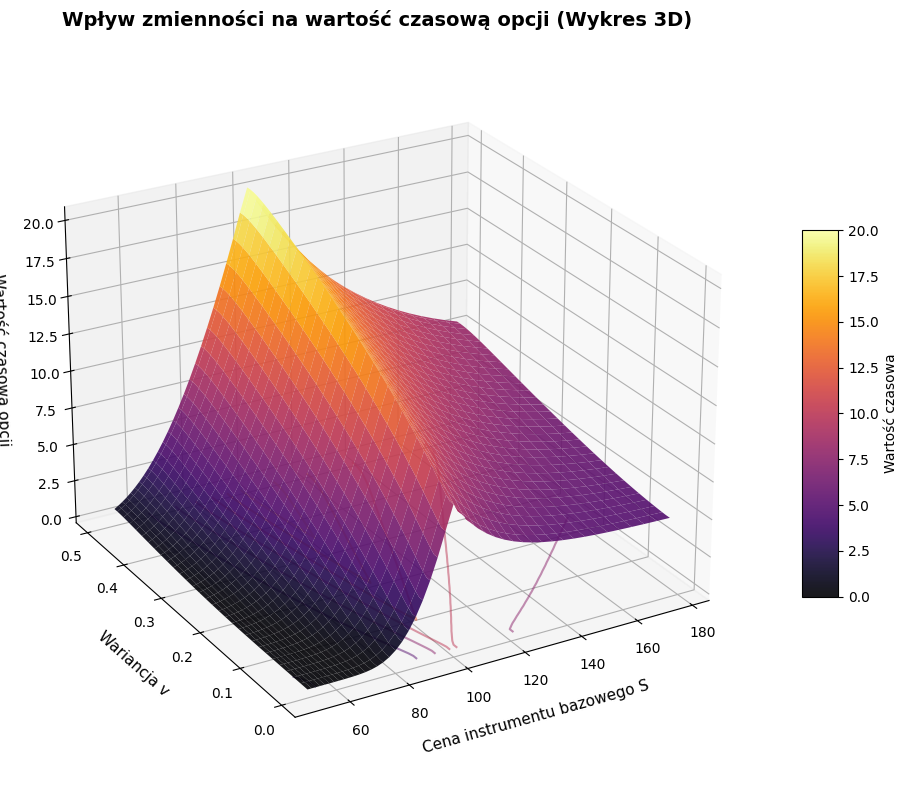

In [6]:
intrinsic_mesh = np.maximum(S_mesh - integrator.K, 0.)
time_value_mesh = V_mesh - intrinsic_mesh

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

surf2 = ax.plot_surface(S_mesh, v_mesh, time_value_mesh, cmap='inferno', edgecolor='none', alpha=0.9)
cset2 = ax.contour(S_mesh, v_mesh, time_value_mesh, zdir='z', offset=0, cmap='inferno', alpha=0.5)

ax.set_xlabel('Cena instrumentu bazowego S', fontsize=11, labelpad=10)
ax.set_ylabel('Wariancja v', fontsize=11, labelpad=10)
ax.set_zlabel('Wartość czasowa opcji', fontsize=11, labelpad=10)
ax.set_title('Wpływ zmienności na wartość czasową opcji (Wykres 3D)', fontsize=14, fontweight='bold', pad=15)

fig.colorbar(surf2, ax=ax, shrink=0.5, aspect=10, label='Wartość czasowa')
ax.view_init(elev=25, azim=-120)

plt.tight_layout()
plt.show()

## Granica Blacka-Scholesa

Dla \(\xi=0\) i \(\theta=v_0\) wariancja jest stała. Model Hestona
powinien wtedy odtworzyć Blacka-Scholesa z
\(\sigma=\sqrt{v_0}\).

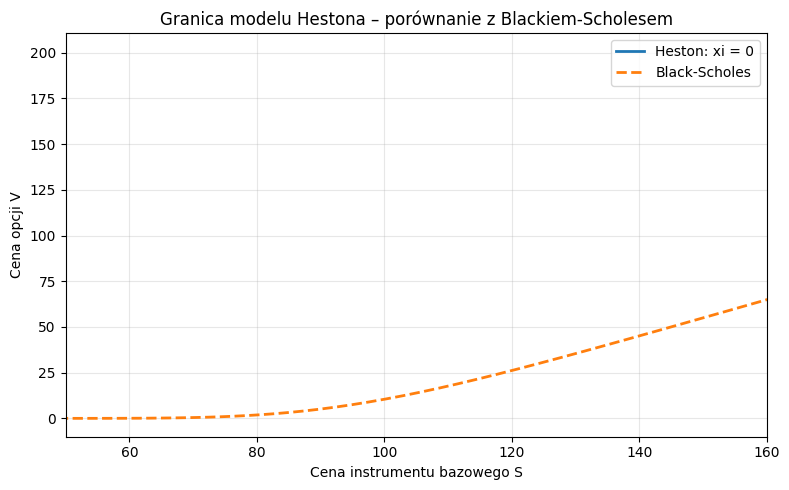

Maksymalna różnica Heston – Black-Scholes: nan


In [7]:
limit_params = params.copy()
limit_params.update(xi=0., rho=0.)

limit_solver, _, limit_output = solve_heston(**limit_params)
V_limit = limit_output[-1]
j = np.argmin(abs(limit_solver.v - limit_params["theta"]))

bs = bs_analytic(limit_solver.S, limit_params["K"], limit_params["T"],
                 limit_params["r"], np.sqrt(limit_params["theta"]))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(limit_solver.S, V_limit[:, j], label="Heston: xi = 0", linewidth=2)
ax.plot(limit_solver.S, bs, "--", label="Black-Scholes", linewidth=2)
ax.set_xlim(50, 160)
ax.set(xlabel="Cena instrumentu bazowego S", ylabel="Cena opcji V",
       title="Granica modelu Hestona – porównanie z Blackiem-Scholesem")
ax.grid(alpha=.3)
ax.legend()
fig.tight_layout()
plt.show()

mask = (limit_solver.S > 50) & (limit_solver.S < 160)
print("Maksymalna różnica Heston – Black-Scholes:",
      np.max(np.abs(V_limit[mask, j] - bs[mask])))

### Synteza wyników do sprawozdania (Wykresy i Porównanie z Blackiem-Scholesem)

Poniższy kod generuje skondensowaną, dwupanelową grafikę o jakości publikacyjnej (idealną do raportu dwustronicowego) oraz oblicza kluczowe metryki dokładności modelu.

 STATYSTYKI PORÓWNANIA Z MODELIEM BLACKA-SCHOLESA (dla xi = 0)
Maksymalny błąd bezwzględny:  nan PLN
Średni błąd kwadratowy (RMSE): nan PLN


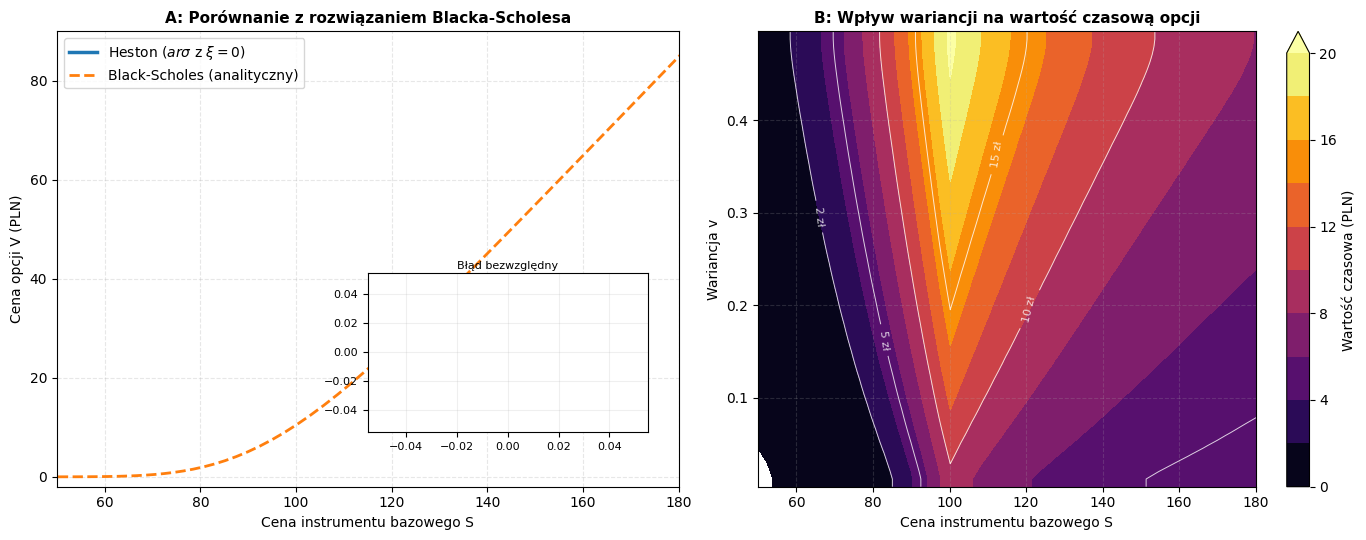

In [8]:
import numpy as np
import matplotlib.pyplot as plt

mask_report = (limit_solver.S >= 50) & (limit_solver.S <= 180)
S_rep = limit_solver.S[mask_report]
Heston_rep = V_limit[mask_report, j]
BS_rep = bs[mask_report]

abs_diff = np.abs(Heston_rep - BS_rep)
max_err = np.max(abs_diff)
rmse = np.sqrt(np.mean(abs_diff**2))

print("="*55)
print(" STATYSTYKI PORÓWNANIA Z MODELIEM BLACKA-SCHOLESA (dla xi = 0)")
print("="*55)
print(f"Maksymalny błąd bezwzględny:  {max_err:.5f} PLN")
print(f"Średni błąd kwadratowy (RMSE): {rmse:.5f} PLN")
print("="*55)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
ax1.plot(limit_solver.S, V_limit[:, j], '-', label=r'Heston ($ar{\sigma}$ z $\xi=0$)', linewidth=2.5, color='#1f77b4')
ax1.plot(limit_solver.S, bs, '--', label='Black-Scholes (analityczny)', linewidth=2, color='#ff7f0e')
ax1.set_xlim(50, 180)
ax1.set_ylim(-2, 90)
ax1.set_xlabel("Cena instrumentu bazowego S", fontsize=10)
ax1.set_ylabel("Cena opcji V (PLN)", fontsize=10)
ax1.set_title("A: Porównanie z rozwiązaniem Blacka-Scholesa", fontsize=11, fontweight='bold')
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.legend(loc='upper left')

ax_inset = ax1.inset_axes([0.5, 0.12, 0.45, 0.35])
ax_inset.plot(S_rep, abs_diff, color='red', linewidth=1.5)
ax_inset.set_title("Błąd bezwzględny", fontsize=8, pad=3)
ax_inset.tick_params(labelsize=8)
ax_inset.grid(True, alpha=0.2)

intrinsic_all = np.maximum(integrator.S[:, None] - integrator.K, 0.)
time_val_all = V - intrinsic_all

levels_tv = np.linspace(0, 20, 11)
im = ax2.contourf(integrator.S, integrator.v, time_val_all.T, levels=levels_tv, cmap="inferno", extend="max")
contours_tv = ax2.contour(integrator.S, integrator.v, time_val_all.T, levels=[2, 5, 10, 15], colors="white", linewidths=0.7, alpha=0.8)
ax2.clabel(contours_tv, inline=True, fontsize=8, fmt="%.0f zł")

fig.colorbar(im, ax=ax2, label="Wartość czasowa (PLN)")
ax2.set_xlim(50, 180)
ax2.set_xlabel("Cena instrumentu bazowego S", fontsize=10)
ax2.set_ylabel("Wariancja v", fontsize=10)
ax2.set_title("B: Wpływ wariancji na wartość czasową opcji", fontsize=11, fontweight='bold')
ax2.grid(True, alpha=0.2, linestyle='--')

plt.tight_layout()
plt.show()